## PREPARACIÓN

Librerías del notebook y sus versiones. La semilla fija los pliegues y cualquier otro paso aleatorio, para que los resultados se repitan al correr todo de nuevo.

In [1]:
# Importar librerías necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("numpy     ", np.__version__)
print("pandas    ", pd.__version__)
print("matplotlib", __import__("matplotlib").__version__)
print("seaborn   ", sns.__version__)
print("sklearn   ", sklearn.__version__)

SEMILLA = 42

numpy      2.4.6
pandas     2.2.3
matplotlib 3.10.0
seaborn    0.13.2
sklearn    1.6.1


## DESCRIPCIÓN DEL PROBLEMA Y DE LOS DATOS

El objetivo es predecir, al cierre del primer semestre, si un estudiante terminará como graduado, desertor o todavía inscrito al final de la duración normal de su carrera. Los datos son de 4424 estudiantes de licenciatura del Instituto Politécnico de Portalegre (Portugal) que ingresaron entre 2008/09 y 2018/19 (UCI, dataset 697).

El curso los entrega en dos archivos. El de entrenamiento trae a 3539 estudiantes con todos sus atributos y la clase (Target). El de prueba trae a 885 estudiantes sin la clase y solo con los atributos que se conocen al cierre del primer semestre.

In [2]:
# Cargar los dos conjuntos con ruta relativa desde la carpeta del repositorio
# df = pd.read_csv("datos/desercion-entrenamiento.csv")
# df_prueba = pd.read_csv("datos/desercion-prueba.csv")

# En Colab, comentar las dos líneas anteriores y descomentar estas
df = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/desercion-entrenamiento.csv")
df_prueba = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/desercion-prueba.csv")

print(f"Entrenamiento: {df.shape[0]} estudiantes × {df.shape[1]} columnas")
print(f"Prueba:        {df_prueba.shape[0]} estudiantes × {df_prueba.shape[1]} columnas")
df.head()

Entrenamiento: 3539 estudiantes × 38 columnas
Prueba:        885 estudiantes × 31 columnas


,id,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,1,1,2,9500,1,1,140.0,1,38,...,0,8,8,8,15.637500,0,13.9,-0.3,0.79,Graduate
1,2,1,17,1,8014,0,1,125.0,1,37,...,0,6,7,6,11.666667,0,10.8,1.4,1.74,Graduate
2,3,1,39,1,9991,0,1,130.0,1,1,...,0,5,12,1,12.000000,0,11.1,0.6,2.02,Dropout
3,4,1,42,1,8014,0,1,150.0,1,19,...,0,6,8,5,12.000000,0,9.4,-0.8,-3.12,Graduate
4,5,2,42,1,9254,1,1,136.0,1,2,...,2,6,12,2,12.500000,0,7.6,2.6,0.32,Dropout


### Revisión general

Dimensiones, tipo de dato, faltantes y duplicados en el dataset de entrenamiento. Como cada estudiante tiene un `id` distinto, una fila repetida nunca contaría como duplicado exacto, así que también se revisan los duplicados sin esa columna.

In [14]:
resumen = pd.Series({
    "registros": df.shape[0],
    "columnas": df.shape[1],
    "numéricas": df.select_dtypes(include="number").shape[1],
    "no numéricas": df.select_dtypes(exclude="number").shape[1],
    "registros con faltantes": df.isna().any(axis=1).sum(),
    "id repetidos": df["id"].duplicated().sum(),
    "duplicados exactos": df.duplicated().sum(),
    "duplicados sin id": df.drop(columns="id").duplicated().sum(),
}, name="entrenamiento")

resumen

,entrenamiento
registros,3539
columnas,38
numéricas,37
no numéricas,1
registros con faltantes,0
id repetidos,0
duplicados exactos,0
duplicados sin id,0


### Información disponible al decidir

Se comparan las columnas de los dos archivos. Las que solo están en el entrenamiento son las que todavía no se conocen al cierre del primer semestre. No se modifica ni utiliza el dataset de prueba, solo es para eliminar la información del segundo semestre.

In [4]:
solo_entrenamiento = [col for col in df.columns if col not in df_prueba.columns]
solo_prueba = [col for col in df_prueba.columns if col not in df.columns]

print("Solo en entrenamiento:")
for col in solo_entrenamiento:
    print("  ", col)
print(f"\nSolo en prueba: {solo_prueba}")

Solo en entrenamiento:
   Curricular units 2nd sem (credited)
   Curricular units 2nd sem (enrolled)
   Curricular units 2nd sem (evaluations)
   Curricular units 2nd sem (approved)
   Curricular units 2nd sem (grade)
   Curricular units 2nd sem (without evaluations)
   Target

Solo en prueba: []


In [5]:
variable_objetivo = "Target"
atributos_segundo = [col for col in df.columns if col not in df_prueba.columns and col != variable_objetivo]

### Distribución de las clases

In [6]:
df[variable_objetivo].value_counts().to_frame("estudiantes").assign(
    proporción=lambda t: (t["estudiantes"] / len(df)).round(3))

,estudiantes,proporción
Target,,
Graduate,1767,0.499
Dropout,1137,0.321
Enrolled,635,0.179


Las clases no están balanceadas. La mitad de los estudiantes se graduó (1767, 49.9 %), un tercio desertó (1137, 32.1 %) y menos de una quinta parte seguía inscrito (635, 17.9 %). Un clasificador que siempre diga «Graduate» ya acierta la mitad de las veces, pero nunca detecta a un desertor ni a un inscrito.

### Tipo de cada atributo

Todos los atributos vienen como números, pero eso no dice su escala. Primero se revisa cuántos valores distintos toma cada uno y su rango; después, con la ficha de UCI, se decide si es nominal, binario, ordinal o continuo.

In [7]:
atributos = df.columns.drop(["id", variable_objetivo])

pd.DataFrame({
    "valores distintos": df[atributos].nunique(),
    "mínimo": df[atributos].min(),
    "máximo": df[atributos].max(),
})

,valores distintos,mínimo,máximo
Marital status,6,1.00,6.000000
Application mode,17,1.00,57.000000
Application order,8,0.00,9.000000
Course,17,33.00,9991.000000
Daytime/evening attendance,2,0.00,1.000000
Previous qualification,17,1.00,43.000000
Previous qualification (grade),100,95.00,190.000000
Nacionality,18,1.00,109.000000
Mother's qualification,26,1.00,44.000000
Father's qualification,32,1.00,44.000000


Las listas por escala, que son las que reciben los `ColumnTransformer` de cada modelo.

In [9]:
nominales = ["Marital status", "Application mode", "Course", "Previous qualification", "Nacionality",
             "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
binarios = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
            "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
ordinales = ["Application order"]
numericos = [col for col in atributos if col not in nominales + binarios + ordinales + atributos_segundo]

print(f"Nominales: {len(nominales)}")
print(f"Binarios:  {len(binarios)}")
print(f"Ordinales: {len(ordinales)}")
print(f"Numéricos: {len(numericos)} (sin los {len(atributos_segundo)} del segundo semestre)")
print(f"Total al cierre del primer semestre: {len(nominales + binarios + ordinales + numericos)}")

Nominales: 9
Binarios:  8
Ordinales: 1
Numéricos: 12 (sin los 6 del segundo semestre)
Total al cierre del primer semestre: 30


### Frecuencia de las categorías

Se grafica cuántos estudiantes hay en cada categoría de los 18 atributos categóricos (nominales, binarios y el ordinal), en el orden de sus códigos.

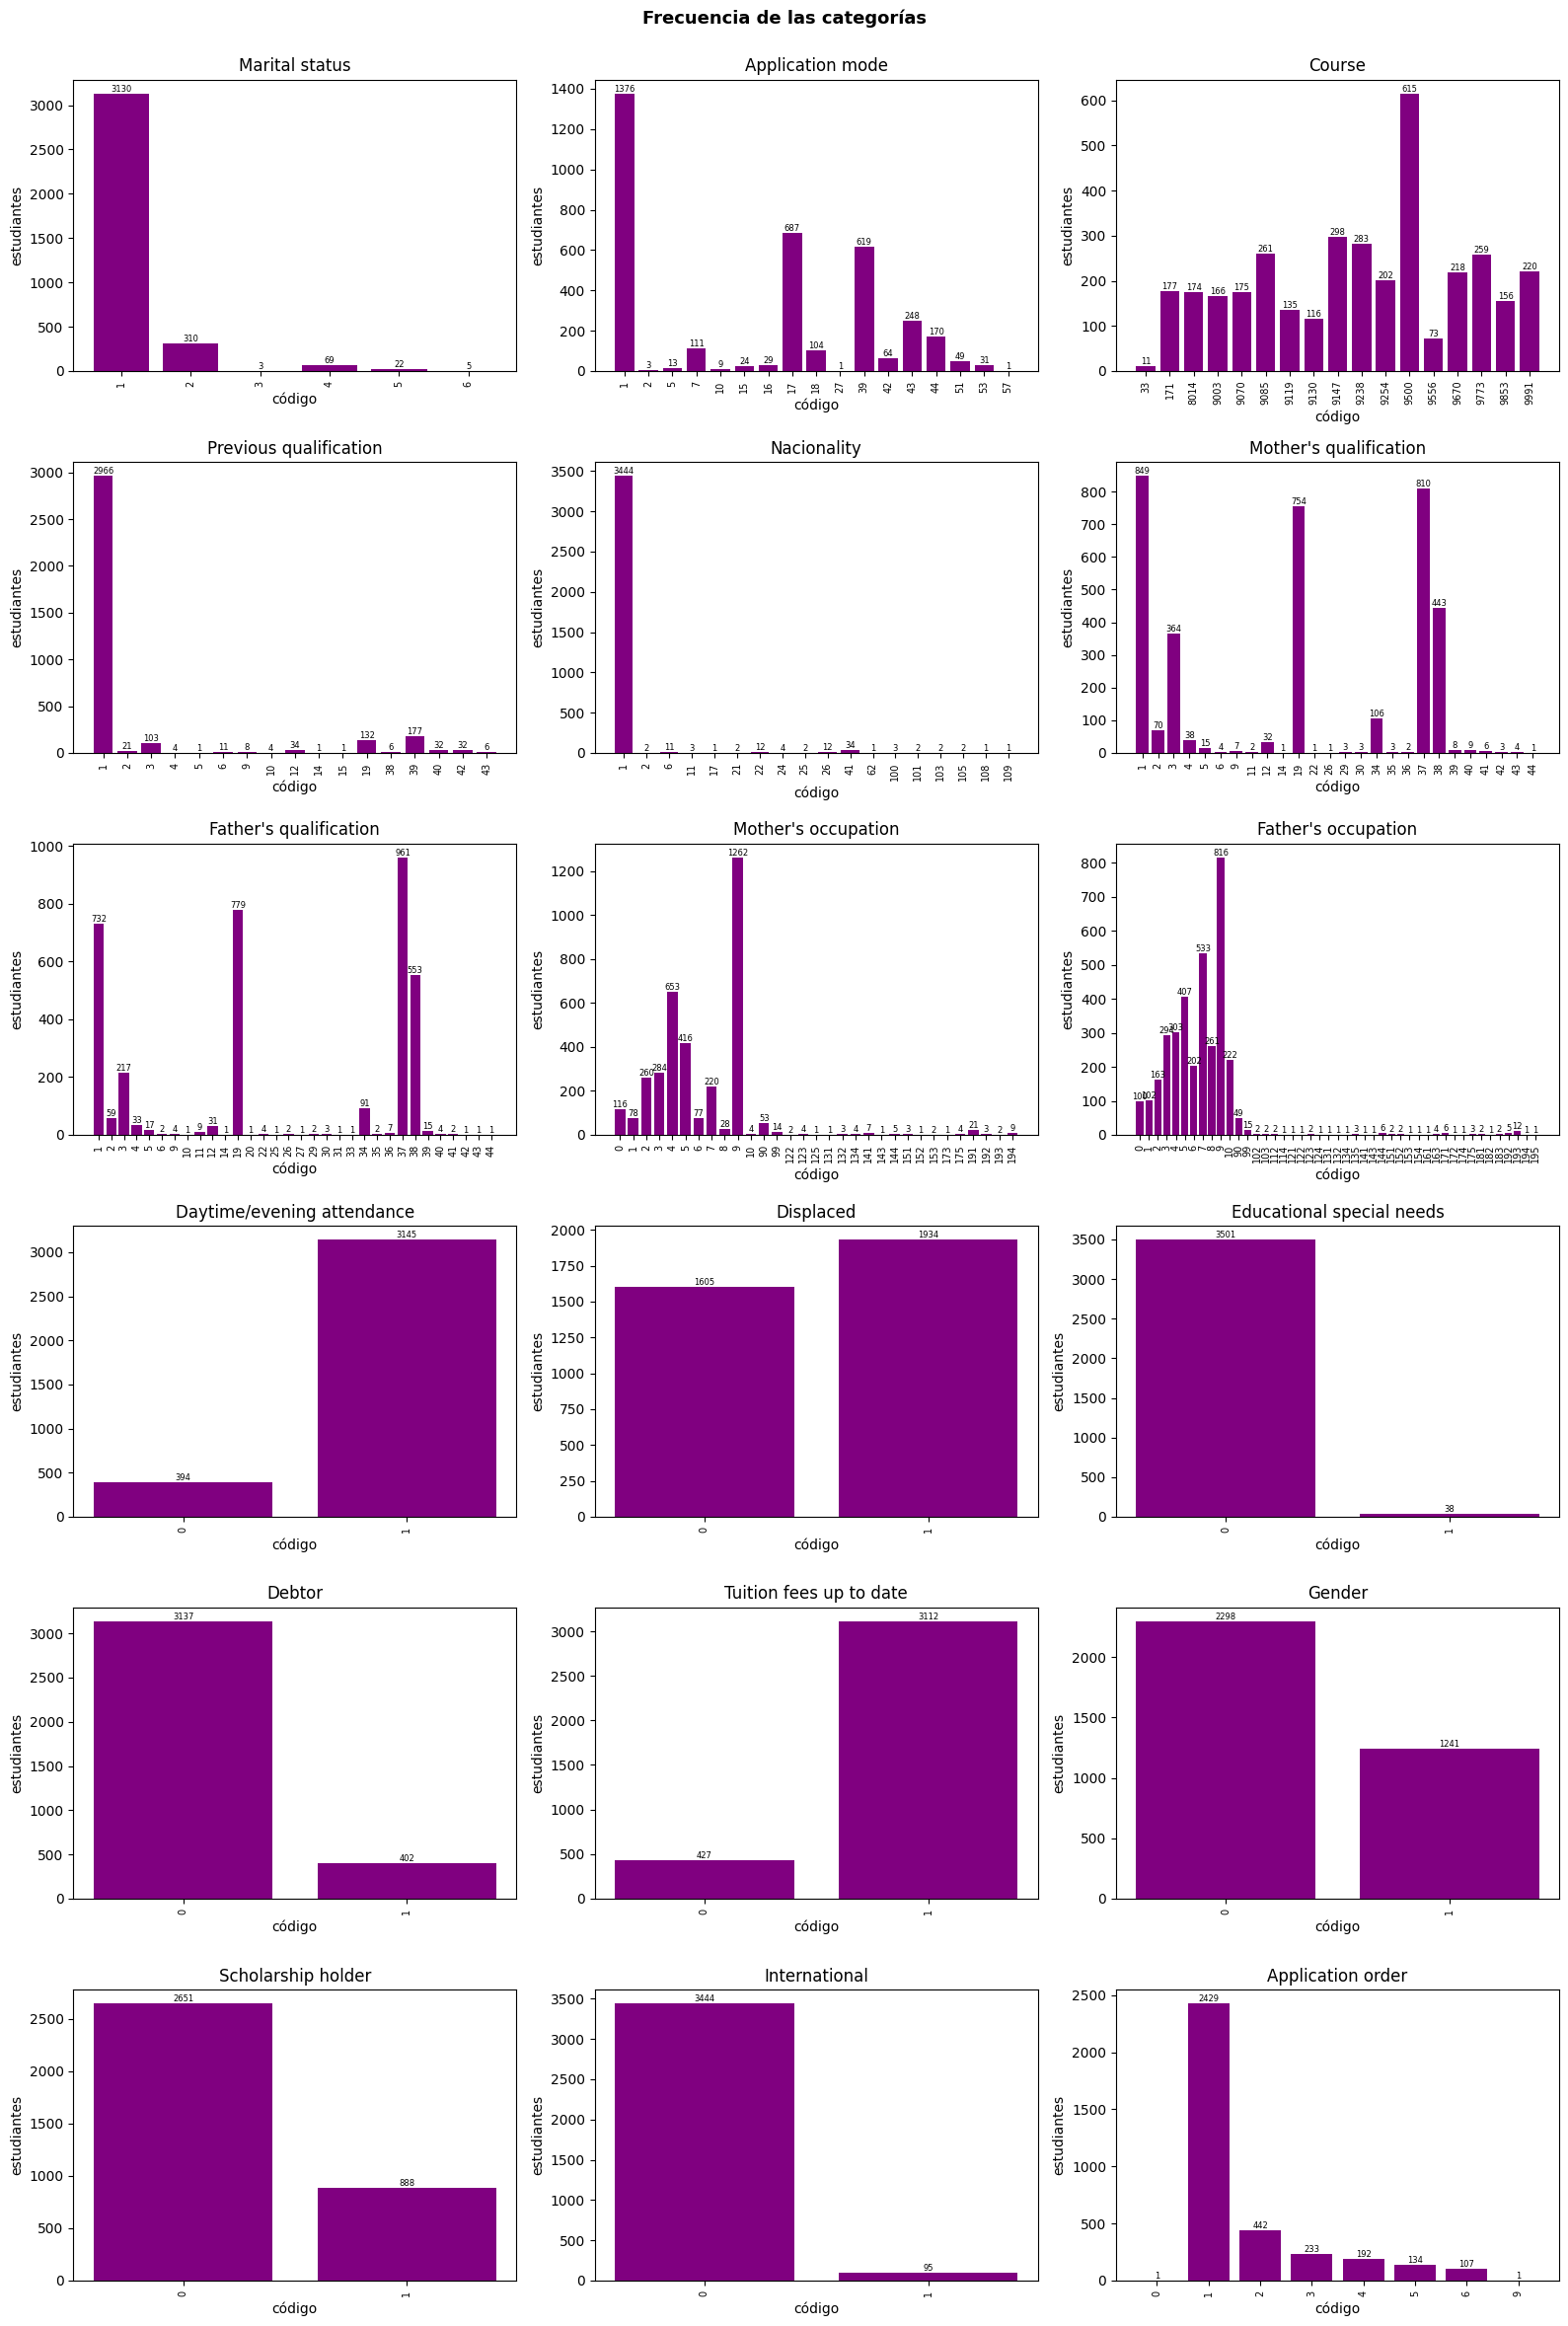

In [11]:
categoricos = nominales + binarios + ordinales

fig, axes = plt.subplots(6, 3, figsize=(16, 24))

for ax, col in zip(axes.ravel(), categoricos):
    conteo = df[col].value_counts().sort_index()
    barras = ax.bar(conteo.index.astype(str), conteo.values, color="purple")
    ax.bar_label(barras, fontsize=6)
    ax.set_title(col)
    ax.set_xlabel("código")
    ax.set_ylabel("estudiantes")
    ax.tick_params(axis="x", rotation=90, labelsize=7)

fig.suptitle("Frecuencia de las categorías", fontsize=13, color="black", fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

Los binarios, el ordinal y la carrera tienen categorías con suficientes estudiantes.

Los demás nominales tienen unas pocas categorías dominantes y una cola larga de categorías con pocos estudiantes (nacionalidad, estudios previos, estudios y ocupación de los padres). Esas categorías pueden faltar en el entrenamiento de algún pliegue, y en el one-hot generan columnas casi vacías.

Por revisar: hay 95 internacionales y 95 con nacionalidad distinta de la 1, quizá son los mismos.

### Nacionalidad e internacional

Se cruzan los dos atributos para ver si los 95 estudiantes internacionales son los mismos 95 con una nacionalidad distinta de la 1.

In [12]:
pd.crosstab(df["Nacionality"] == 1, df["International"],
            rownames=["nacionalidad 1"], colnames=["International"])

International,0,1
nacionalidad 1,,
False,0,95
True,3444,0


Son los mismos. Los 95 internacionales son exactamente los 95 con nacionalidad distinta de la 1, así que `International` repite información de `Nacionality`.

Por lo tanto, se descarta `Nacionality`. Parte de su información útil ya está en `International`, y el resto son nacionalidades con muy pocos estudiantes.

In [13]:
nominales.remove("Nacionality")
print(f"Nominales: {len(nominales)}")

Nominales: 8


### Distribución de los atributos numéricos

Histogramas de los 12 atributos numéricos disponibles al cierre del primer semestre.

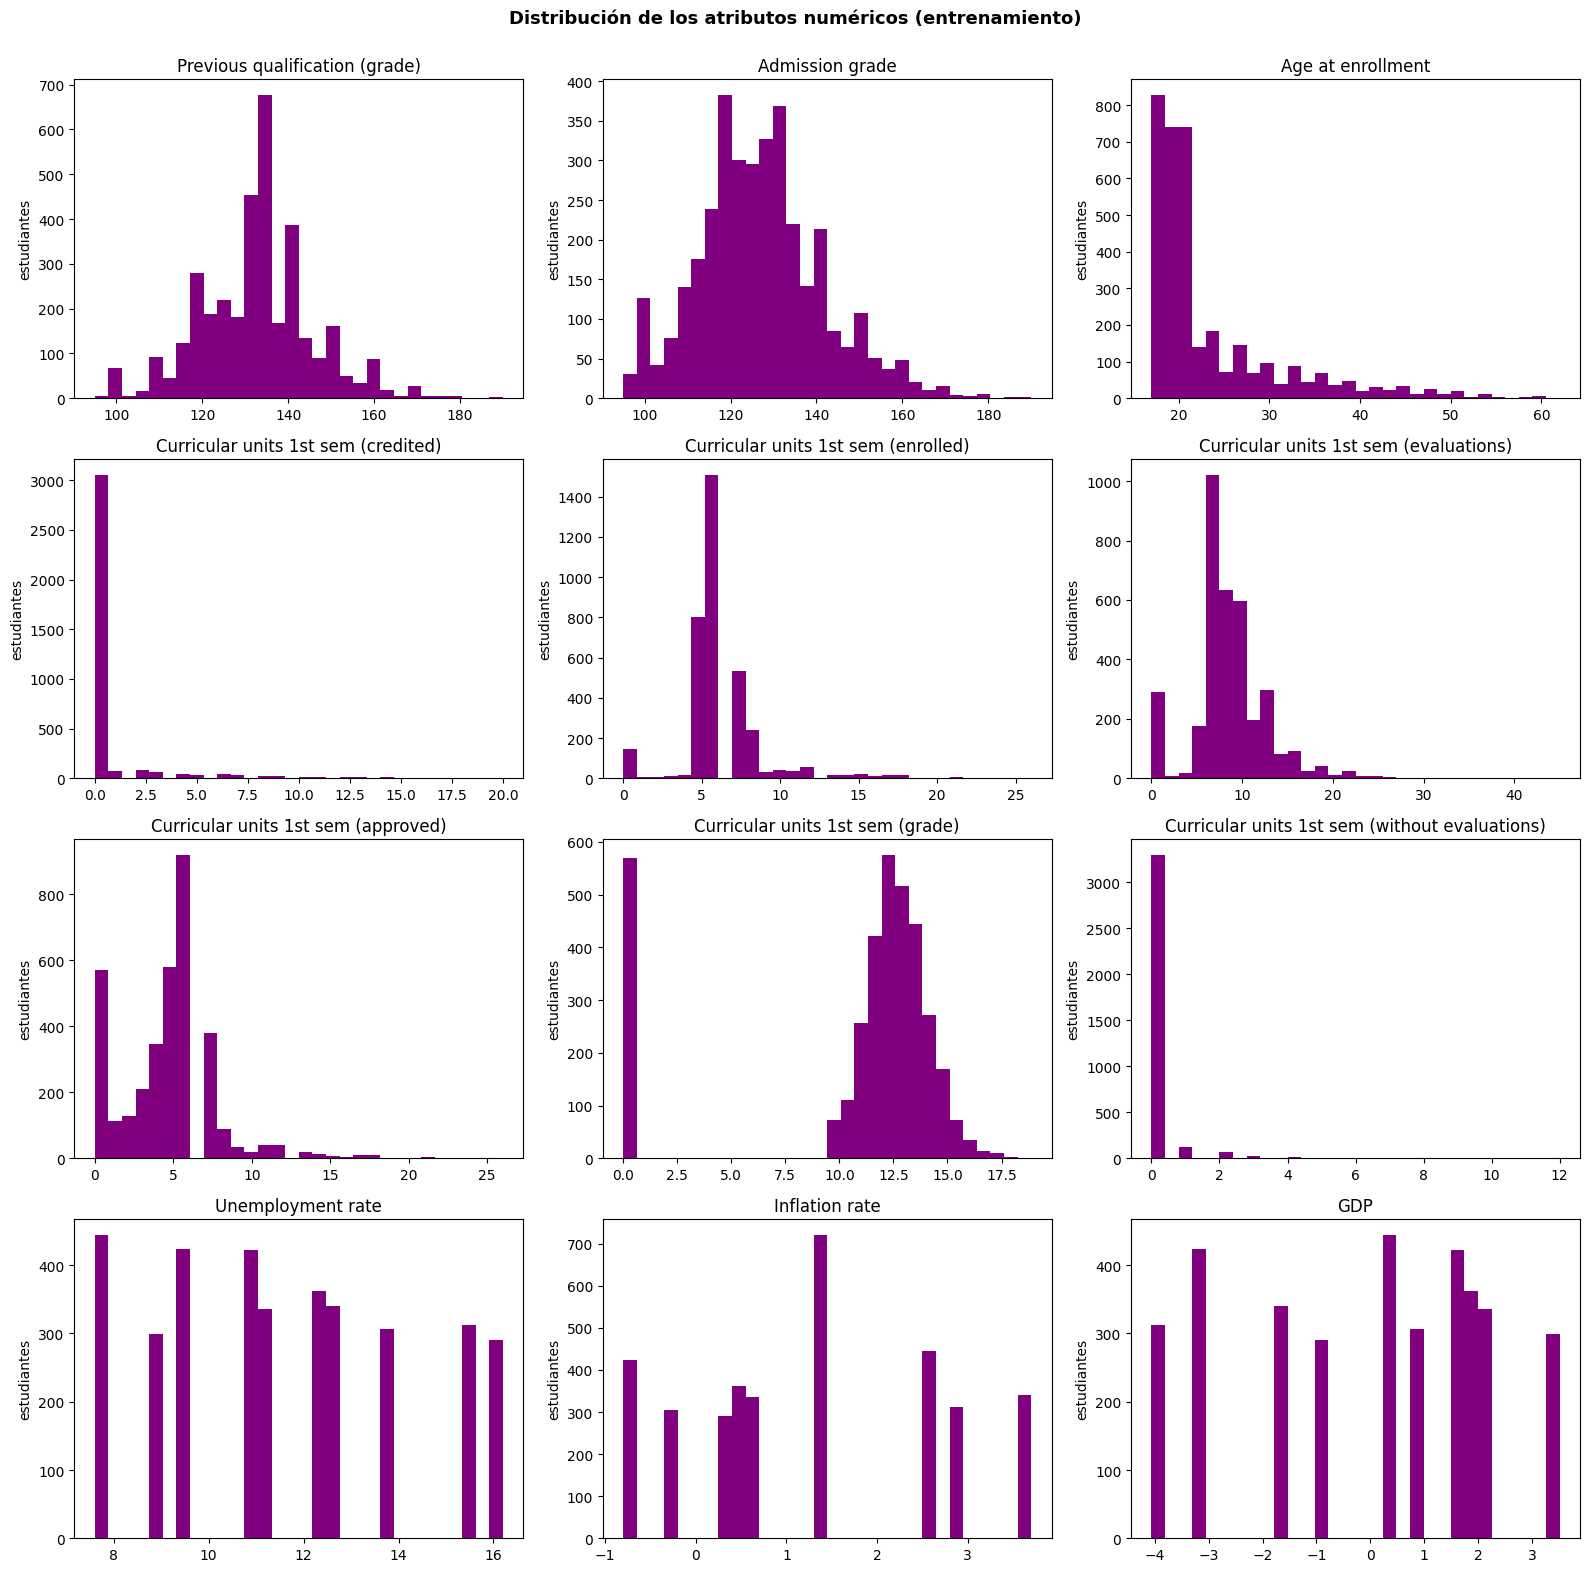

In [15]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16))

for ax, col in zip(axes.ravel(), numericos):
    ax.hist(df[col], bins=30, color="purple")
    ax.set_title(col)
    ax.set_ylabel("estudiantes")

fig.suptitle("Distribución de los atributos numéricos (entrenamiento)", fontsize=13, color="black", fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

Las calificaciones previas y de admisión tienen forma de campana, entre 95 y 190.

La edad está cargada a la izquierda. Las unidades acreditadas y sin evaluación valen 0 en casi todos. El promedio del primer semestre tiene unos 570 estudiantes en 0 y el resto entre 10 y 18, sin nada en medio. Los tres indicadores económicos son pocos valores sueltos.

Las escalas son muy distintas (de −4 a 3 en el PIB, de 95 a 190 en las calificaciones), lo que confirma que kNN, SVM y regresión logística necesitarán escalamiento.

## IMPLEMENTACIÓN
Los atributos son los 29 disponibles al cierre del primer semestre (sin `Nacionality`). Los 3539 estudiantes se reparten en 5 pliegues estratificados, que se guardan para que los cinco clasificadores se evalúen exactamente con la misma partición.

In [17]:
from sklearn.model_selection import StratifiedKFold

atributos_primer = nominales + binarios + ordinales + numericos
X = df[atributos_primer]
y = df[variable_objetivo]

pliegues = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X, y))

pd.DataFrame({f"pliegue {i + 1}": y.iloc[validacion].value_counts(normalize=True)
              for i, (_, validacion) in enumerate(pliegues)}).round(3)

,pliegue 1,pliegue 2,pliegue 3,pliegue 4,pliegue 5
Target,,,,,
Graduate,0.500,0.500,0.499,0.499,0.499
Dropout,0.321,0.321,0.322,0.322,0.321
Enrolled,0.179,0.179,0.179,0.179,0.180


### Línea base

El clasificador que ignora los atributos y predice siempre la clase más frecuente. Es el número que cualquier modelo tiene que superar.

In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

base = cross_validate(DummyClassifier(strategy="most_frequent"), X, y, cv=pliegues,
                      scoring=["accuracy", "f1_macro"])

print(f"Exactitud: {base['test_accuracy'].mean():.3f}")
print(f"F1 macro:  {base['test_f1_macro'].mean():.3f} ± {base['test_f1_macro'].std():.3f}")

Exactitud: 0.499
F1 macro:  0.222 ± 0.000


La línea base acierta 49.9 % prediciendo siempre «Graduate», pero su F1 macro es 0.222, porque nunca detecta a un desertor ni a un inscrito.

## ÁRBOL DE DECISIÓN

### Preprocesamiento

Los nominales van en one-hot. Los binarios, el ordinal y los numéricos entran sin cambios.

Si en un pliegue de validación aparece una categoría que no estaba en el entrenamiento, recibe ceros en todas las columnas de su atributo. Además, la búsqueda prueba dos opciones para las categorías raras, dejarlas cada una en su columna o juntar en una sola columna las que tienen menos de 10 estudiantes, y la validación decide cuál conviene.

### Búsqueda

Criterio, profundidad máxima, poda por costo-complejidad y pesos por clase.

In [19]:
import time
from sklearn.compose import make_column_transformer
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

arbol = make_pipeline(
    make_column_transformer(
        (OneHotEncoder(handle_unknown="infrequent_if_exist", sparse_output=False), nominales),
        ("passthrough", binarios + ordinales + numericos)),
    DecisionTreeClassifier(random_state=SEMILLA))

malla_arbol = {
    "columntransformer__onehotencoder__min_frequency": [None, 10],
    "decisiontreeclassifier__criterion": ["gini", "entropy"],
    "decisiontreeclassifier__max_depth": [3, 4, 5, 6, 8, 10, None],
    "decisiontreeclassifier__ccp_alpha": [0, 0.001, 0.003, 0.01],
    "decisiontreeclassifier__class_weight": [None, "balanced"],
}

inicio = time.perf_counter()
busqueda_arbol = GridSearchCV(arbol, malla_arbol, cv=pliegues, scoring="f1_macro", n_jobs=-1).fit(X, y)
tiempo_arbol = time.perf_counter() - inicio

print(f"Configuraciones evaluadas: {len(busqueda_arbol.cv_results_['params'])}")
print(f"Tiempo de búsqueda: {tiempo_arbol:.1f} s")
print(f"Mejor F1 macro: {busqueda_arbol.best_score_:.3f} ± "
      f"{busqueda_arbol.cv_results_['std_test_score'][busqueda_arbol.best_index_]:.3f}")
{k.split("__")[-1]: v for k, v in busqueda_arbol.best_params_.items()}

Configuraciones evaluadas: 224
Tiempo de búsqueda: 40.9 s
Mejor F1 macro: 0.639 ± 0.013


{'min_frequency': None,
 'ccp_alpha': 0.003,
 'class_weight': 'balanced',
 'criterion': 'gini',
 'max_depth': 4}

El mejor árbol logra un F1 macro de 0.639 ± 0.013. Es un árbol chico (profundidad 4, Gini, poda con α = 0.003), con pesos balanceados por clase y sin agrupar categorías raras. La búsqueda de 224 configuraciones tardó 40.9 s.

### Hiperparámetro más influyente

Para cada valor de un hiperparámetro se toma el mejor F1 macro que se alcanza con él. La diferencia entre su mejor y su peor valor indica cuánto se pierde si ese hiperparámetro se elige mal. El de mayor diferencia es el que va en la gráfica de meseta.

In [26]:
def influencia(busqueda):
    resultados = pd.DataFrame(busqueda.cv_results_)
    diferencias = {}
    for col in [c for c in resultados.columns if c.startswith("param_")]:
        validos = resultados[resultados[col].notna()]
        mejor_por_valor = validos.groupby(validos[col].astype(str))["mean_test_score"].max()
        diferencias[col.replace("param_", "").split("__")[-1]] = mejor_por_valor.max() - mejor_por_valor.min()
    return pd.Series(diferencias, name="diferencia en F1 macro").sort_values(ascending=False).round(3)

influencia(busqueda_arbol)

,diferencia en F1 macro
max_depth,0.018
ccp_alpha,0.007
criterion,0.000
min_frequency,0.000
class_weight,0.000


La profundidad es el hiperparámetro más influyente (0.018 de diferencia en F1 macro).

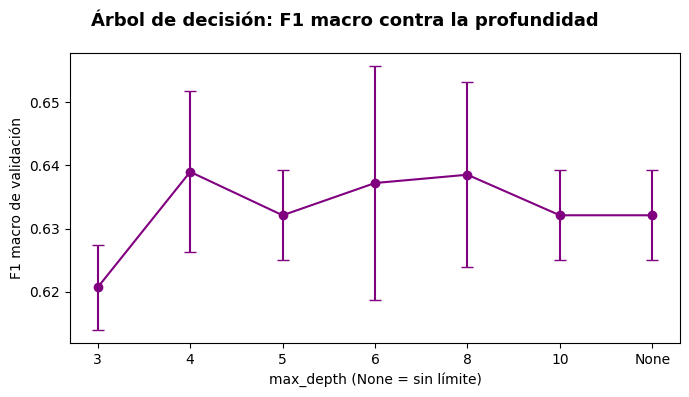

In [21]:
resultados_arbol = pd.DataFrame(busqueda_arbol.cv_results_)
param = "param_decisiontreeclassifier__max_depth"
profundidades = [str(p) for p in malla_arbol["decisiontreeclassifier__max_depth"]]

indices = resultados_arbol.groupby(resultados_arbol[param].astype(str))["mean_test_score"].idxmax()
mejores = resultados_arbol.loc[indices].set_index(resultados_arbol.loc[indices, param].astype(str)).reindex(profundidades)

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(profundidades, mejores["mean_test_score"], yerr=mejores["std_test_score"],
            color="purple", marker="o", capsize=4)
ax.set_xlabel("max_depth (None = sin límite)")
ax.set_ylabel("F1 macro de validación")
fig.suptitle("Árbol de decisión: F1 macro contra la profundidad", fontsize=13, color="black", fontweight="bold")
plt.tight_layout()
plt.show()

El F1 macro sube de 0.621 con profundidad 3 a 0.639 con profundidad 4, y de ahí en adelante se queda entre 0.632 y 0.639. Esas diferencias son menores que la desviación entre pliegues (0.007 a 0.019), así que la búsqueda llegó a una meseta. Con profundidad 10 o sin límite el resultado es el mismo, porque la poda ya limita el tamaño del árbol.

## NAIVE BAYES

### Naive Bayes mixto

sklearn tiene un Naive Bayes para atributos categóricos (`CategoricalNB`) y otro para continuos (`GaussianNB`), pero ninguno para los dos a la vez. Como en el notebook 14, se combinan sumando las log-probabilidades de cada uno y restando una vez la previa, que los dos cuentan. La clase solo envuelve esa cuenta para que funcione dentro de un Pipeline. Recibe primero las columnas categóricas y después las continuas.

In [22]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.naive_bayes import CategoricalNB, GaussianNB

class NaiveBayesMixto(ClassifierMixin, BaseEstimator):
    def __init__(self, n_categoricos=0, alpha=1.0, var_smoothing=1e-9, min_categories=None):
        self.n_categoricos = n_categoricos
        self.alpha = alpha
        self.var_smoothing = var_smoothing
        self.min_categories = min_categories

    def fit(self, X, y):
        X = np.asarray(X)
        self.cnb_ = CategoricalNB(alpha=self.alpha, min_categories=self.min_categories).fit(X[:, :self.n_categoricos], y)
        self.gnb_ = GaussianNB(var_smoothing=self.var_smoothing).fit(X[:, self.n_categoricos:], y)
        self.classes_ = self.gnb_.classes_
        return self

    def predict_proba(self, X):
        X = np.asarray(X)
        log_conjunta = (self.cnb_.predict_joint_log_proba(X[:, :self.n_categoricos])
                        + self.gnb_.predict_joint_log_proba(X[:, self.n_categoricos:])
                        - np.log(self.gnb_.class_prior_))
        proba = np.exp(log_conjunta - log_conjunta.max(axis=1, keepdims=True))
        return proba / proba.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

### Preprocesamiento

Los 17 atributos categóricos (nominales, binarios y el ordinal) van a la parte categórica con `OrdinalEncoder`. Aquí los códigos sí se valen, porque `CategoricalNB` solo los usa como etiquetas para contar. Una categoría que no apareció en el entrenamiento de un pliegue recibe un código extra de "desconocida", que el suavizado deja con probabilidad pequeña pero no cero.

Los 12 numéricos se tratan de dos formas, y esa es la variante que se busca.
- **Mixto.** Los numéricos van a la parte gaussiana, sin transformar o con Yeo-Johnson para acercarlos a una campana, porque la exploración mostró asimetrías y picos en 0.
- **Discretizado.** Los numéricos se cortan en intervalos con el mismo número de estudiantes y todo va a `CategoricalNB`.

### Búsqueda

La variante, el suavizado de la parte categórica (`alpha`), el de la parte gaussiana (`var_smoothing`) y el número de intervalos.

In [24]:
import warnings
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, OrdinalEncoder, PowerTransformer

categoricos_nb = nominales + binarios + ordinales
desconocida = df[categoricos_nb].nunique().max()   # código para categorías no vistas, mayor que cualquier código real

codificador = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=desconocida, dtype=int)
prepara_mixto = ColumnTransformer([("categoricos", codificador, categoricos_nb),
                                   ("numericos", "passthrough", numericos)])
prepara_discreto = ColumnTransformer([("categoricos", codificador, categoricos_nb),
                                      ("numericos", KBinsDiscretizer(encode="ordinal", strategy="quantile"), numericos)])

naive_bayes = Pipeline([("prepara", prepara_mixto), ("nb", NaiveBayesMixto())])

malla_nb = [
    {"prepara": [prepara_mixto],
     "prepara__numericos": ["passthrough", PowerTransformer()],
     "nb": [NaiveBayesMixto(n_categoricos=len(categoricos_nb), min_categories=desconocida + 1)],
     "nb__alpha": [0.1, 0.3, 1, 3, 10],
     "nb__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3]},
    {"prepara": [prepara_discreto],
     "prepara__numericos__n_bins": [3, 5, 8, 10, 15],
     "nb": [CategoricalNB(min_categories=desconocida + 1)],
     "nb__alpha": [0.1, 0.3, 1, 3, 10]},
]

inicio = time.perf_counter()
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Bins whose width are too small")   # intervalos vacíos que se juntan
    busqueda_nb = GridSearchCV(naive_bayes, malla_nb, cv=pliegues, scoring="f1_macro", n_jobs=-1).fit(X, y)
tiempo_nb = time.perf_counter() - inicio

print(f"Configuraciones evaluadas: {len(busqueda_nb.cv_results_['params'])}")
print(f"Tiempo de búsqueda: {tiempo_nb:.1f} s")
print(f"Mejor F1 macro: {busqueda_nb.best_score_:.3f} ± "
      f"{busqueda_nb.cv_results_['std_test_score'][busqueda_nb.best_index_]:.3f}")
print(f"Variante: {type(busqueda_nb.best_params_['nb']).__name__}")
{k: v for k, v in busqueda_nb.best_params_.items() if k not in ["prepara", "nb"]}

Configuraciones evaluadas: 65
Tiempo de búsqueda: 14.1 s
Mejor F1 macro: 0.619 ± 0.012
Variante: CategoricalNB


{'nb__alpha': 0.3, 'prepara__numericos__n_bins': 10}

El mejor Naive Bayes es la variante discretizada (`CategoricalNB` con 10 intervalos por atributo numérico y `alpha` = 0.3), con F1 macro de 0.619 ± 0.012, por debajo del árbol (0.639). La búsqueda de 65 configuraciones tardó 14.1 s.

In [27]:
influencia(busqueda_nb)

,diferencia en F1 macro
alpha,0.136
n_bins,0.011
nb,0.008
prepara,0.008
numericos,0.005
var_smoothing,0.001


El suavizado (`alpha`) es el hiperparámetro más influyente, con 0.136 de diferencia en F1 macro.

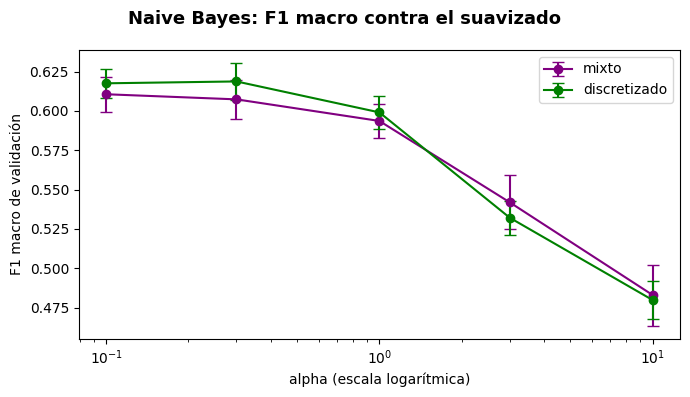

In [28]:
resultados_nb = pd.DataFrame(busqueda_nb.cv_results_)
resultados_nb["variante"] = resultados_nb["param_nb"].apply(lambda m: type(m).__name__)

fig, ax = plt.subplots(figsize=(7, 4))

for variante, nombre, color in [("NaiveBayesMixto", "mixto", "purple"), ("CategoricalNB", "discretizado", "green")]:
    sub = resultados_nb[resultados_nb["variante"] == variante]
    mejores = sub.loc[sub.groupby("param_nb__alpha")["mean_test_score"].idxmax()]
    ax.errorbar(mejores["param_nb__alpha"].astype(float), mejores["mean_test_score"], yerr=mejores["std_test_score"],
                color=color, marker="o", capsize=4, label=nombre)

ax.set_xscale("log")
ax.set_xlabel("alpha (escala logarítmica)")
ax.set_ylabel("F1 macro de validación")
ax.legend()
fig.suptitle("Naive Bayes: F1 macro contra el suavizado", fontsize=13, color="black", fontweight="bold")
plt.tight_layout()
plt.show()

Las dos variantes llegan a una meseta con suavizado bajo (0.1 y 0.3), donde el discretizado queda en 0.618 a 0.619 y el mixto en 0.607 a 0.611. Con `alpha` de 1 en adelante el F1 macro cae hasta 0.48, porque el suavizado aplana las probabilidades de las categorías. La diferencia entre las dos variantes (unos 0.01) es menor que la desviación entre pliegues.

## K VECINOS MÁS CERCANOS

### Preprocesamiento

kNN clasifica por distancias, así que la escala decide quiénes son los vecinos. Los nominales van en one-hot, porque restar códigos no tiene sentido. Los binarios ya están en 0 y 1 y entran sin cambios. El ordinal y los numéricos se escalan, y la búsqueda decide entre estandarizar o llevarlos a [0, 1]. Como en el árbol, la validación decide si se agrupan las categorías raras.

### Búsqueda

El número de vecinos (k), la ponderación (uniforme o por distancia) y la distancia (Manhattan, p = 1, o euclidiana, p = 2).

In [31]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler

knn = Pipeline([
    ("prepara", ColumnTransformer([
        ("nominales", OneHotEncoder(handle_unknown="infrequent_if_exist", sparse_output=False), nominales),
        ("binarios", "passthrough", binarios),
        ("numericos", StandardScaler(), ordinales + numericos)])),
    ("knn", KNeighborsClassifier())])

comunes = {
    "prepara__nominales__min_frequency": [None, 10],
    "prepara__numericos": [StandardScaler(), MinMaxScaler()],
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 51, 71, 101],
    "knn__weights": ["uniform", "distance"],
}
malla_knn = [
    {**comunes, "knn__p": [2]},
    {**comunes, "knn__p": [1], "knn__algorithm": ["ball_tree"]},   # evita un error de sklearn 1.6.1 con Manhattan y pesos uniformes
]

inicio = time.perf_counter()
busqueda_knn = GridSearchCV(knn, malla_knn, cv=pliegues, scoring="f1_macro", n_jobs=-1).fit(X, y)
tiempo_knn = time.perf_counter() - inicio

print(f"Configuraciones evaluadas: {len(busqueda_knn.cv_results_['params'])}")
print(f"Tiempo de búsqueda: {tiempo_knn:.1f} s")
print(f"Mejor F1 macro: {busqueda_knn.best_score_:.3f} ± "
      f"{busqueda_knn.cv_results_['std_test_score'][busqueda_knn.best_index_]:.3f}")
{k.split("__")[-1]: v for k, v in busqueda_knn.best_params_.items()}

Configuraciones evaluadas: 208
Tiempo de búsqueda: 164.7 s
Mejor F1 macro: 0.568 ± 0.013


{'algorithm': 'ball_tree',
 'n_neighbors': 7,
 'p': 1,
 'weights': 'uniform',
 'min_frequency': 10,
 'numericos': StandardScaler()}

El mejor kNN usa 7 vecinos con distancia Manhattan, pesos uniformes, numéricos estandarizados y categorías raras agrupadas, con F1 macro de 0.568 ± 0.013. Queda por debajo del árbol (0.639) y de Naive Bayes (0.619). La búsqueda tardó 164.7 s, la más lenta hasta ahora, porque kNN calcula distancias contra todos los estudiantes de entrenamiento en cada predicción.

In [32]:
influencia(busqueda_knn)

,diferencia en F1 macro
n_neighbors,0.102
numericos,0.061
weights,0.006
p,0.002
min_frequency,0.000
algorithm,0.000


El número de vecinos es el más influyente (0.102).

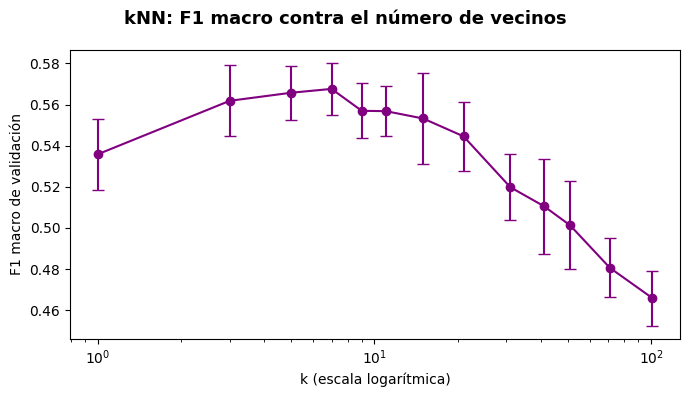

In [33]:
resultados_knn = pd.DataFrame(busqueda_knn.cv_results_)
param = "param_knn__n_neighbors"

mejores = resultados_knn.loc[resultados_knn.groupby(param)["mean_test_score"].idxmax()]

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(mejores[param].astype(int), mejores["mean_test_score"], yerr=mejores["std_test_score"],
            color="purple", marker="o", capsize=4)
ax.set_xscale("log")
ax.set_xlabel("k (escala logarítmica)")
ax.set_ylabel("F1 macro de validación")
fig.suptitle("kNN: F1 macro contra el número de vecinos", fontsize=13, color="black", fontweight="bold")
plt.tight_layout()
plt.show()

El F1 macro sube de 0.536 con k = 1 a 0.568 con k = 7, se mantiene entre 0.553 y 0.568 de k = 3 a k = 15, y después cae hasta 0.466 con k = 101. El máximo queda dentro del rango probado, con valores menores a los dos lados, así que la búsqueda lo encontró. Con pocos vecinos el modelo depende de unos cuantos estudiantes, y con muchos mezcla estudiantes que ya no se parecen.

## SVM

### Preprocesamiento

El kernel RBF mide distancias, igual que kNN, así que los nominales van en one-hot y el ordinal y los numéricos se estandarizan. Los binarios entran sin cambios. Como en los modelos anteriores, la validación decide si se agrupan las categorías raras.

### Búsqueda

El kernel (lineal o RBF), C, gamma (solo con RBF) y los pesos por clase.

In [34]:
from sklearn.svm import SVC

svm = Pipeline([
    ("prepara", ColumnTransformer([
        ("nominales", OneHotEncoder(handle_unknown="infrequent_if_exist", sparse_output=False), nominales),
        ("binarios", "passthrough", binarios),
        ("numericos", StandardScaler(), ordinales + numericos)])),
    ("svc", SVC(random_state=SEMILLA))])

malla_svm = [
    {"prepara__nominales__min_frequency": [None, 10],
     "svc__kernel": ["rbf"],
     "svc__C": [0.1, 0.3, 1, 3, 10, 30, 100],
     "svc__gamma": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3],
     "svc__class_weight": [None, "balanced"]},
    {"prepara__nominales__min_frequency": [None, 10],
     "svc__kernel": ["linear"],
     "svc__C": [0.01, 0.1, 1, 10],
     "svc__class_weight": [None, "balanced"]},
]

inicio = time.perf_counter()
busqueda_svm = GridSearchCV(svm, malla_svm, cv=pliegues, scoring="f1_macro", n_jobs=-1).fit(X, y)
tiempo_svm = time.perf_counter() - inicio

print(f"Configuraciones evaluadas: {len(busqueda_svm.cv_results_['params'])}")
print(f"Tiempo de búsqueda: {tiempo_svm:.1f} s")
print(f"Mejor F1 macro: {busqueda_svm.best_score_:.3f} ± "
      f"{busqueda_svm.cv_results_['std_test_score'][busqueda_svm.best_index_]:.3f}")
{k.split("__")[-1]: v for k, v in busqueda_svm.best_params_.items()}

Configuraciones evaluadas: 184
Tiempo de búsqueda: 661.7 s
Mejor F1 macro: 0.688 ± 0.006


{'min_frequency': None,
 'C': 30,
 'class_weight': 'balanced',
 'gamma': 0.003,
 'kernel': 'rbf'}

El mejor SVM usa kernel RBF con C = 30, gamma = 0.003, pesos balanceados por clase y sin agrupar categorías raras. Su F1 macro es 0.688 ± 0.006, el más alto hasta ahora, por encima del árbol (0.639), Naive Bayes (0.619) y kNN (0.568). También es el más lento, porque la búsqueda de 184 configuraciones tardó 661.7 s (unos 11 minutos).

In [35]:
influencia(busqueda_svm)

,diferencia en F1 macro
gamma,0.148
C,0.034
kernel,0.016
min_frequency,0.000
class_weight,0.000


Gamma es el hiperparámetro más influyente (0.148).

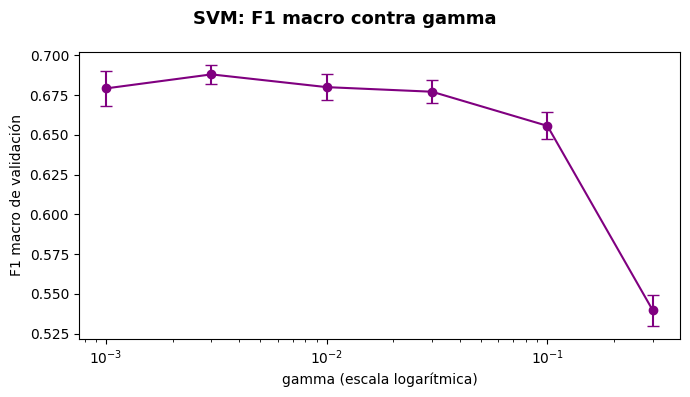

In [36]:
resultados_svm = pd.DataFrame(busqueda_svm.cv_results_)
param = "param_svc__gamma"
rbf = resultados_svm[resultados_svm[param].notna()]

mejores = rbf.loc[rbf.groupby(param)["mean_test_score"].idxmax()]

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(mejores[param].astype(float), mejores["mean_test_score"], yerr=mejores["std_test_score"],
            color="purple", marker="o", capsize=4)
ax.set_xscale("log")
ax.set_xlabel("gamma (escala logarítmica)")
ax.set_ylabel("F1 macro de validación")
fig.suptitle("SVM: F1 macro contra gamma", fontsize=13, color="black", fontweight="bold")
plt.tight_layout()
plt.show()

El F1 macro se mantiene entre 0.677 y 0.688 con gamma de 0.001 a 0.03, con el máximo en 0.003, y después cae a 0.656 con 0.1 y a 0.540 con 0.3.

## REGRESIÓN LOGÍSTICA

### Preprocesamiento

El mismo que el SVM. La regularización castiga el tamaño de los coeficientes, y ese castigo solo es parejo si todos los atributos están en la misma escala, así que el ordinal y los numéricos se estandarizan. Los nominales van en one-hot y los binarios entran sin cambios. La validación decide si se agrupan las categorías raras.

### Búsqueda

C (inverso de la fuerza de la regularización), el tipo de regularización (L1 o L2) y los pesos por clase. La L1 se ajusta con el solver `saga`, el único que la admite con tres clases; la L2, con `lbfgs`, que es más rápido. La agrupación de categorías raras se quitó de esta malla porque la búsqueda tardaba mucho más que la de los otros modelos, y en el árbol, kNN y el SVM no cambió el F1 macro.

In [40]:
from sklearn.linear_model import LogisticRegression

logistica = Pipeline([
    ("prepara", ColumnTransformer([
        ("nominales", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominales),
        ("binarios", "passthrough", binarios),
        ("numericos", StandardScaler(), ordinales + numericos)])),
    ("logistica", LogisticRegression(max_iter=5000, random_state=SEMILLA))])

comunes = {
    "logistica__C": [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100],
    "logistica__class_weight": [None, "balanced"],
}
malla_logistica = [
    {**comunes, "logistica__penalty": ["l2"], "logistica__solver": ["lbfgs"]},
    {**comunes, "logistica__penalty": ["l1"], "logistica__solver": ["saga"], "logistica__tol": [1e-3]},
]

inicio = time.perf_counter()
busqueda_logistica = GridSearchCV(logistica, malla_logistica, cv=pliegues, scoring="f1_macro",
                                  n_jobs=-1, verbose=2).fit(X, y)
tiempo_logistica = time.perf_counter() - inicio

print(f"Configuraciones evaluadas: {len(busqueda_logistica.cv_results_['params'])}")
print(f"Tiempo de búsqueda: {tiempo_logistica:.1f} s")
print(f"Mejor F1 macro: {busqueda_logistica.best_score_:.3f} ± "
      f"{busqueda_logistica.cv_results_['std_test_score'][busqueda_logistica.best_index_]:.3f}")
{k.split("__")[-1]: v for k, v in busqueda_logistica.best_params_.items()}

Fitting 5 folds for each of 52 candidates, totalling 260 fits
Configuraciones evaluadas: 52
Tiempo de búsqueda: 255.4 s
Mejor F1 macro: 0.682 ± 0.008


{'C': 0.3,
 'class_weight': 'balanced',
 'penalty': 'l1',
 'solver': 'saga',
 'tol': 0.001}

La mejor regresión logística usa regularización L1 con C = 0.3 y pesos balanceados por clase, con F1 macro de 0.682 ± 0.008. Queda muy cerca del SVM (0.688) y por encima del árbol (0.639), Naive Bayes (0.619) y kNN (0.568). La búsqueda de 52 configuraciones tardó 255.4 s.

In [41]:
influencia(busqueda_logistica)

,diferencia en F1 macro
C,0.084
penalty,0.002
solver,0.002
class_weight,0.000
tol,0.000


C es el hiperparámetro más influyente (0.084).

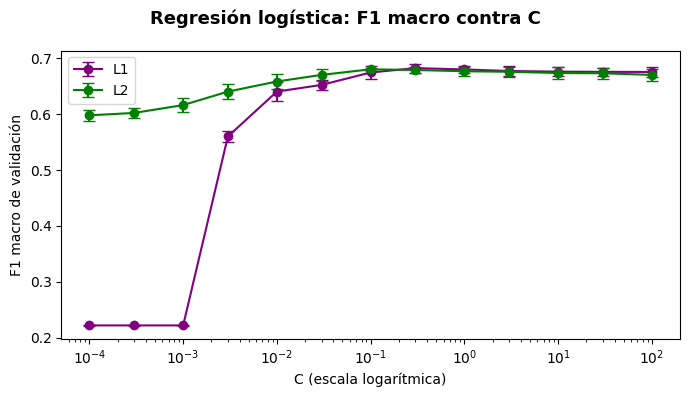

In [42]:
resultados_logistica = pd.DataFrame(busqueda_logistica.cv_results_)
param = "param_logistica__C"

fig, ax = plt.subplots(figsize=(7, 4))

for penalizacion, color in [("l1", "purple"), ("l2", "green")]:
    sub = resultados_logistica[resultados_logistica["param_logistica__penalty"] == penalizacion]
    mejores = sub.loc[sub.groupby(param)["mean_test_score"].idxmax()]
    ax.errorbar(mejores[param].astype(float), mejores["mean_test_score"], yerr=mejores["std_test_score"],
                color=color, marker="o", capsize=4, label=penalizacion.upper())

ax.set_xscale("log")
ax.set_xlabel("C (escala logarítmica)")
ax.set_ylabel("F1 macro de validación")
ax.legend()
fig.suptitle("Regresión logística: F1 macro contra C", fontsize=13, color="black", fontweight="bold")
plt.tight_layout()
plt.show()

Con C de 0.1 en adelante, L1 y L2 quedan en una meseta entre 0.67 y 0.68. Con C bajo se separan. L2 baja poco, hasta 0.60, mientras que L1 con C de 0.001 o menos cae a 0.222, el F1 de la línea base, porque la regularización deja todos los coeficientes en cero y el modelo predice siempre la clase mayoritaria.

## COMPARACIÓN DE LOS CLASIFICADORES

Para cada clasificador optimizado, el F1 macro de validación con su desviación entre pliegues, la sensibilidad y la especificidad de cada clase y el tiempo de la búsqueda. La sensibilidad y la especificidad salen de las predicciones de validación cruzada con los mismos pliegues; la especificidad se calcula con la matriz de confusión de cada clase contra el resto.

In [43]:
from sklearn.metrics import multilabel_confusion_matrix
from sklearn.model_selection import cross_val_predict

CLASES = ["Graduate", "Dropout", "Enrolled"]
busquedas = {
    "árbol": (busqueda_arbol, tiempo_arbol),
    "Naive Bayes": (busqueda_nb, tiempo_nb),
    "kNN": (busqueda_knn, tiempo_knn),
    "SVM": (busqueda_svm, tiempo_svm),
    "regresión logística": (busqueda_logistica, tiempo_logistica),
}

predicciones = {}
filas = {}
for nombre, (busqueda, tiempo) in busquedas.items():
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="Bins whose width are too small")
        predicciones[nombre] = cross_val_predict(busqueda.best_estimator_, X, y, cv=pliegues, n_jobs=-1)
    fila = {"F1 macro": busqueda.best_score_,
            "desv. est.": busqueda.cv_results_["std_test_score"][busqueda.best_index_]}
    for clase, m in zip(CLASES, multilabel_confusion_matrix(y, predicciones[nombre], labels=CLASES)):
        tn, fp, fn, tp = m.ravel()
        fila[f"sens. {clase}"] = tp / (tp + fn)
        fila[f"esp. {clase}"] = tn / (tn + fp)
    fila["tiempo (s)"] = tiempo
    filas[nombre] = fila

comparacion = pd.DataFrame(filas).T.sort_values("F1 macro", ascending=False)
comparacion.round(3)

,F1 macro,desv. est.,sens. Graduate,esp. Graduate,sens. Dropout,esp. Dropout,sens. Enrolled,esp. Enrolled,tiempo (s)
SVM,0.688,0.006,0.810,0.845,0.672,0.932,0.608,0.821,661.679
regresión logística,0.682,0.008,0.799,0.842,0.693,0.924,0.576,0.824,255.425
árbol,0.639,0.013,0.808,0.783,0.651,0.912,0.457,0.833,40.869
Naive Bayes,0.619,0.012,0.784,0.761,0.718,0.836,0.351,0.898,14.078
kNN,0.568,0.013,0.893,0.593,0.580,0.904,0.214,0.927,164.658


El SVM tiene el mejor F1 macro (0.688 ± 0.006), seguido de cerca por la logística (0.682 ± 0.008); la diferencia es del tamaño de la desviación entre pliegues, así que en la práctica empatan. Los dos detectan mejor que los demás a los inscritos (sensibilidad de 0.608 y 0.576).

`Enrolled` es la clase más difícil para todos, con sensibilidad de 0.214 (kNN) a 0.608 (SVM). kNN predice «Graduate» de más, con la sensibilidad de graduados más alta (0.893) pero la especificidad más baja (0.593). Naive Bayes detecta más desertores (0.718), a cambio de más falsas alarmas (especificidad de 0.836).

Tiempo. El SVM es el más lento (661.7 s), contra 255.4 s de la logística y 40.9 s del árbol.

Con el F1 macro como métrica principal, el mejor clasificador es el SVM.

## MATRIZ DE CONFUSIÓN DEL MEJOR CLASIFICADOR

Matriz del SVM con las predicciones de validación cruzada, es decir, cada estudiante clasificado por el modelo entrenado sin él.

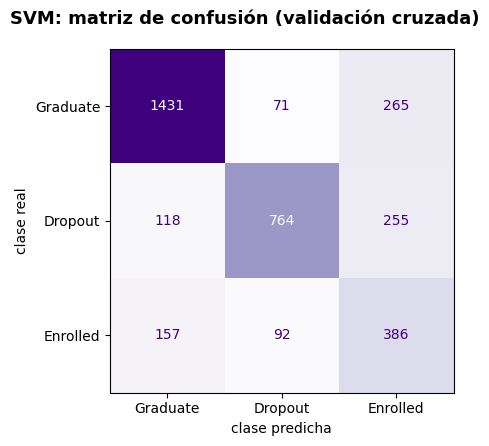

In [44]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

matriz_svm = confusion_matrix(y, predicciones["SVM"], labels=CLASES)

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(matriz_svm, display_labels=CLASES).plot(ax=ax, cmap="Purples", colorbar=False)
ax.set_xlabel("clase predicha")
ax.set_ylabel("clase real")
fig.suptitle("SVM: matriz de confusión (validación cruzada)", fontsize=13, color="black", fontweight="bold")
plt.tight_layout()
plt.show()

De los 1137 desertores, el SVM detecta 764. De los 373 que no detecta, 255 los clasifica como inscritos y 118 como graduados, así que el desertor se confunde sobre todo con el inscrito. En la otra dirección pasa lo mismo, porque de los 927 estudiantes que predice como desertores, 92 eran inscritos y 71 graduados. Inscritos y desertores también se confunden con los graduados (265 graduados predichos como inscritos).

### Por qué se confunde el desertor

Mediana de cada atributo numérico en cinco grupos, según la clase real y la predicha. Si los desertores clasificados como inscritos se parecen más a los inscritos que a los desertores detectados, el modelo no tiene con qué distinguirlos al cierre del primer semestre.

In [45]:
grupo = y + " → " + pd.Series(predicciones["SVM"], index=y.index)
grupos = ["Dropout → Dropout", "Dropout → Enrolled", "Dropout → Graduate", "Enrolled → Enrolled", "Graduate → Graduate"]

X[numericos].groupby(grupo).median().loc[grupos].T.round(1)

,Dropout → Dropout,Dropout → Enrolled,Dropout → Graduate,Enrolled → Enrolled,Graduate → Graduate
Previous qualification (grade),133.1,130.0,133.1,130.0,133.1
Admission grade,122.0,124.1,130.0,122.5,128.4
Age at enrollment,26.0,20.0,19.0,20.0,19.0
Curricular units 1st sem (credited),0.0,0.0,0.0,0.0,0.0
Curricular units 1st sem (enrolled),6.0,6.0,6.0,6.0,6.0
Curricular units 1st sem (evaluations),7.0,10.0,8.0,10.0,7.0
Curricular units 1st sem (approved),0.0,4.0,6.0,4.0,6.0
Curricular units 1st sem (grade),0.0,11.7,12.9,12.0,13.2
Curricular units 1st sem (without evaluations),0.0,0.0,0.0,0.0,0.0
Unemployment rate,11.1,10.8,11.1,11.1,11.1


Los desertores que el SVM detecta reprobaron todo el primer semestre (mediana de 0 unidades aprobadas y promedio 0) y son mayores (mediana de 26 años). Los que confunde con inscritos se ven igual que los inscritos (4 unidades aprobadas, promedio de 11.7 contra 12.0, 10 evaluaciones y 20 años en los dos grupos), y los que confunde con graduados se ven como graduados (6 aprobadas, promedio de 12.9 contra 13.2, 19 años). Es decir, al cierre del primer semestre esos desertores todavía no muestran señales de abandono; su deserción ocurre después, con información que el modelo aún no tiene.

## ¿CONVIENE ESPERAR AL SEGUNDO SEMESTRE?

El SVM se reentrena con sus mismos hiperparámetros, agregando los seis atributos del segundo semestre, y se evalúa con los mismos 5 pliegues. Como solo cambia la información disponible, la diferencia en F1 macro es la ganancia de esperar. Los nuevos atributos son numéricos y se estandarizan como los demás.

In [46]:
X_segundo = df[atributos_primer + atributos_segundo]

svm_segundo = Pipeline([
    ("prepara", ColumnTransformer([
        ("nominales", OneHotEncoder(handle_unknown="infrequent_if_exist", sparse_output=False), nominales),
        ("binarios", "passthrough", binarios),
        ("numericos", StandardScaler(), ordinales + numericos + atributos_segundo)])),
    ("svc", SVC(random_state=SEMILLA))]).set_params(**busqueda_svm.best_params_)

cv_segundo = cross_validate(svm_segundo, X_segundo, y, cv=pliegues, scoring="f1_macro", n_jobs=-1)

f1_primero = [busqueda_svm.cv_results_[f"split{i}_test_score"][busqueda_svm.best_index_] for i in range(5)]
por_pliegue = pd.DataFrame({"primer semestre": f1_primero, "segundo semestre": cv_segundo["test_score"]},
                           index=[f"pliegue {i + 1}" for i in range(5)])
por_pliegue["diferencia"] = por_pliegue["segundo semestre"] - por_pliegue["primer semestre"]
por_pliegue.loc["media"] = por_pliegue.mean()
por_pliegue.round(3)

,primer semestre,segundo semestre,diferencia
pliegue 1,0.698,0.718,0.019
pliegue 2,0.682,0.729,0.047
pliegue 3,0.688,0.714,0.026
pliegue 4,0.682,0.718,0.036
pliegue 5,0.690,0.718,0.028
media,0.688,0.719,0.031


Esperar al segundo semestre mejora el F1 macro en los cinco pliegues, de 0.019 a 0.047, y en promedio sube de 0.688 a 0.719 (+0.031). Como la mejora aparece en todos los pliegues, no es ruido de la partición.

Sensibilidad y especificidad por clase con cada semestre, para ver en qué clase está la mejora:

In [47]:
pred_segundo = cross_val_predict(svm_segundo, X_segundo, y, cv=pliegues, n_jobs=-1)

fila = {}
for clase, m in zip(CLASES, multilabel_confusion_matrix(y, pred_segundo, labels=CLASES)):
    tn, fp, fn, tp = m.ravel()
    fila[f"sens. {clase}"] = tp / (tp + fn)
    fila[f"esp. {clase}"] = tn / (tn + fp)

semestres = pd.DataFrame({"primer semestre": comparacion.loc["SVM", fila.keys()], "segundo semestre": fila}).T
semestres.round(3)

,sens. Graduate,esp. Graduate,sens. Dropout,esp. Dropout,sens. Enrolled,esp. Enrolled
primer semestre,0.810,0.845,0.672,0.932,0.608,0.821
segundo semestre,0.825,0.869,0.719,0.938,0.643,0.837


Mejoran las seis métricas. La mayor ganancia está en la sensibilidad de `Dropout`, que sube de 0.672 a 0.719, lo que equivale a detectar unos 50 desertores más de los 1137. La de `Enrolled` sube de 0.608 a 0.643. Las especificidades mejoran poco (de 0.006 a 0.024).

### Discusión

Esperar mejora el modelo, pero poco. El F1 macro sube 0.031 y se detectan unos 50 desertores más. Esa ganancia tiene un costo, porque la predicción llega un semestre después, con menos tiempo para intervenir, y algunos de esos estudiantes pueden haber abandonado durante el segundo semestre.

Además, los desertores más claros ya se detectan al cierre del primer semestre, porque reprueban todo. Los que el segundo semestre ayuda a encontrar son los que en el primero se veían como inscritos o graduados.

Por eso no conviene esperar para decidir. Lo razonable es usar el modelo del primer semestre para intervenir pronto y volver a evaluar al cierre del segundo, cuando aparecen las señales de los desertores que el primero no ve.

## CLASIFICADOR FINAL

El SVM optimizado, que `GridSearchCV` ya reentrenó con los 3539 estudiantes, predice a los 885 de prueba con los mismos 29 atributos del primer semestre. Las predicciones se guardan con las columnas `id` y `Target`, en minúsculas como pide la consigna.

In [48]:
modelo_final = busqueda_svm.best_estimator_
prediccion_prueba = modelo_final.predict(df_prueba[atributos_primer])

salida = pd.DataFrame({"id": df_prueba["id"], "Target": pd.Series(prediccion_prueba).str.lower()})
salida.to_csv("predicciones.csv", index=False)

print(f"Estudiantes: {len(salida)}")
salida["Target"].value_counts()

Estudiantes: 885


,count
Target,
graduate,430
enrolled,238
dropout,217


## DISCUSIÓN Y CONCLUSIONES

El SVM con kernel RBF fue el mejor (F1 macro de 0.688 ± 0.006), seguido por la regresión logística (0.682 ± 0.008); la diferencia es del tamaño del ruido entre pliegues. Los dos se benefician de los pesos balanceados y de atributos estandarizados, y son los que mejor detectan a los inscritos. La logística es más rápida (255 s contra 662 s), y con la regularización L1 descarta atributos.

El árbol (0.639) quedó en un punto medio. Rinde mejor con poca profundidad (4 niveles) y es el más rápido entre los que superan 0.6, pero detecta pocos inscritos (0.457).

Naive Bayes (0.619) es el que más desertores detecta (0.718), a cambio de más falsas alarmas. La variante discretizada ganó por poco a la mixta, y el suavizado bajo fue lo que más importó.

kNN (0.568) fue el peor. Tiende a predecir «Graduate», la clase mayoritaria, y casi no detecta inscritos (0.214). Al comparar distancias con 29 atributos en one-hot y escalados, los vecinos se definen sobre todo por atributos que no separan las clases.

En todos los modelos la clase más difícil es `Enrolled`, y el desertor se confunde sobre todo con ella. Al cierre del primer semestre, los desertores que no se detectan tienen el mismo desempeño académico que los inscritos. Esperar al segundo semestre mejora el F1 macro del SVM de 0.688 a 0.719 en los cinco pliegues, pero retrasa la intervención un semestre.

## DECLARACIÓN DE USO DE IA

Este notebook se elaboró con apoyo de Claude (Anthropic) para estructurar el código y la redacción. Las decisiones de análisis, la ejecución y la revisión de los resultados son responsabilidad del autor.